# COMP9085 Week 2 Laboratory
## Diagnostic Model Auditor: decision trees on real biological data

**Two hours. Bring your answers to the questions in bold; they are the point of
the session, not the code.**

You are auditing a model. By the end you will have grown a decision tree on
real diagnostic data, found where it stops generalising, looked inside it,
traced a real case through it, deployed it, and written the document that says
what it must not be used for.

**Dataset.** Wisconsin Diagnostic Breast Cancer (WDBC): 569 cases, 30 features,
212 malignant and 357 benign. Real benchmark data, used here for educational
machine-learning experimentation.

**This is not a clinical diagnostic system.** Nothing you build today is
validated for any clinical use, and Task 10 asks you to write that down
properly.

---

### Before you start

```
pip install numpy pandas scikit-learn matplotlib
```

Everything runs on a laptop in under a minute. No GPU, no internet after the
first import.

---

# SOLUTIONS

Lecturer copy. Do not publish this notebook on the course website.

### Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

SEED = 42          # fix it once, here, and never silently change it
np.random.seed(SEED)

data = load_breast_cancer()
X = data.data
y = 1 - data.target          # recode so 1 = malignant, the clinical positive
feature_names = list(data.feature_names)
print("X", X.shape, "  y", y.shape)

X (569, 30)   y (569,)


## Task 1 — Meet the data

Before fitting anything, look at what you have. A model you cannot describe is
a model you cannot audit.

Report the shape, the class distribution, the feature types, and the
**majority-class baseline**: the accuracy you get by predicting the commoner
class for every case.

**Question 1.1.** What does one row of this matrix physically correspond to,
and who produced the numbers?

**Question 1.2.** Why must every accuracy you report later be compared against
the baseline rather than against 50 per cent?

samples          569
features         30
malignant        212
benign           357
majority baseline  0.6274   (always predict benign)
all features numeric: True


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,malignant
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,malignant
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,malignant
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,malignant
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,malignant


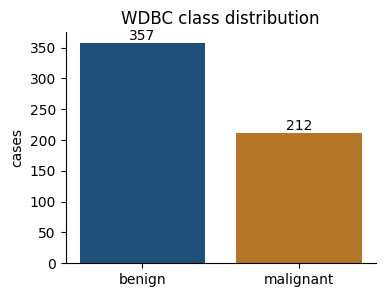

In [2]:
n, p = X.shape
n_malignant = int(y.sum())
n_benign = int((1 - y).sum())
baseline = max(n_malignant, n_benign) / n

print(f"samples          {n}")
print(f"features         {p}")
print(f"malignant        {n_malignant}")
print(f"benign           {n_benign}")
print(f"majority baseline{baseline:>8.4f}   (always predict benign)")
print(f"all features numeric: {np.issubdtype(X.dtype, np.number)}")

df = pd.DataFrame(X, columns=feature_names)
df["diagnosis"] = np.where(y == 1, "malignant", "benign")
display(df.head())

fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(["benign", "malignant"], [n_benign, n_malignant],
       color=["#1f4e79", "#b5762a"])
for i, v in enumerate([n_benign, n_malignant]):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_ylabel("cases")
ax.set_title("WDBC class distribution")
ax.spines[["top", "right"]].set_visible(False)
plt.show()

# 1.1  One row is one fine-needle aspirate of a breast mass. A person traced
#      the boundary of each cell nucleus in the image; ten measurements were
#      computed per nucleus and summarised three ways (mean, standard error,
#      worst), giving 30 features. The numbers are the output of a human
#      tracing step, which is the first place error can enter.
# 1.2  Because the classes are not balanced. 62.7 per cent accuracy is free:
#      you get it by never looking at the data. A model reporting 65 per cent
#      has added almost nothing, and only the comparison shows that.

## Task 2 — Grow a tree

Split the data **once**, stratified, 70/30, with `random_state=SEED`. Fit a
`DecisionTreeClassifier` with `criterion="entropy"` and **no depth limit**.

Report the depth, the number of nodes and leaves, and the training and
held-out accuracy. Then **visualise the tree**.

**Question 2.1.** The training accuracy will be 100 per cent. Is that good
news?

**Question 2.2.** `DecisionTreeClassifier` is not an implementation of ID3.
Name two concrete differences you can see in the tree you just drew.

train 398   held out 171
depth            8
nodes            31
leaves           16
train accuracy   1.0000
held-out accuracy   0.9415


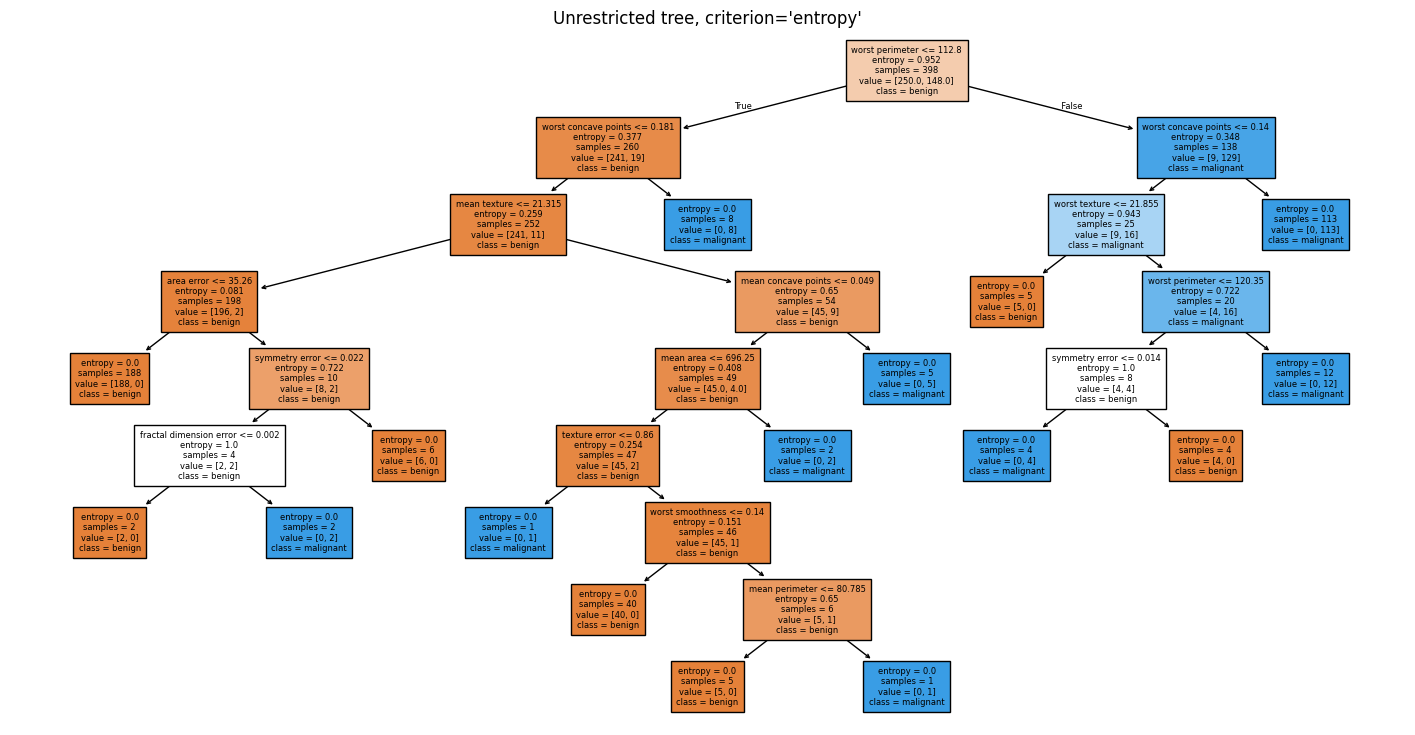

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=SEED)
print(f"train {X_train.shape[0]}   held out {X_test.shape[0]}")

full = DecisionTreeClassifier(criterion="entropy", random_state=SEED)
full.fit(X_train, y_train)

print(f"depth            {full.get_depth()}")
print(f"nodes            {full.tree_.node_count}")
print(f"leaves           {full.get_n_leaves()}")
print(f"train accuracy   {full.score(X_train, y_train):.4f}")
print(f"held-out accuracy{full.score(X_test, y_test):>9.4f}")

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(full, feature_names=feature_names,
          class_names=["benign", "malignant"], filled=True, fontsize=6, ax=ax)
ax.set_title("Unrestricted tree, criterion='entropy'")
plt.show()

# 2.1  No. 100 per cent on the training set means the tree has grown a leaf for
#      every awkward case, including the noise. The only number that carries
#      information is the held-out one, and the gap between the two is the
#      overfitting.
# 2.2  (i) Every node has exactly two children: CART splits binary, ID3 grows
#      one branch per level of a categorical feature. (ii) The same feature
#      appears more than once down a single path, which ID3 forbids because it
#      removes a feature once it has been used.

## Task 3 — Investigate overfitting

Train a tree at every depth from 1 to 12. Record training and held-out
accuracy at each. Plot both curves on the same axes.

**Question 3.1.** At which depth do the curves separate, and what is happening
to the tree at that point?

**Question 3.2.** Which depth would you choose, and what is wrong with the way
you just chose it? (Task 8 fixes this.)

,depth,train,test,leaves
0,1,0.9296,0.8947,2
1,2,0.9497,0.9064,4
2,3,0.9623,0.9181,6
3,4,0.9749,0.9298,9
4,5,0.9899,0.9415,12
5,6,0.9975,0.9357,14
6,7,0.9975,0.9415,15
7,8,1.0000,0.9415,16
8,9,1.0000,0.9415,16
9,10,1.0000,0.9415,16


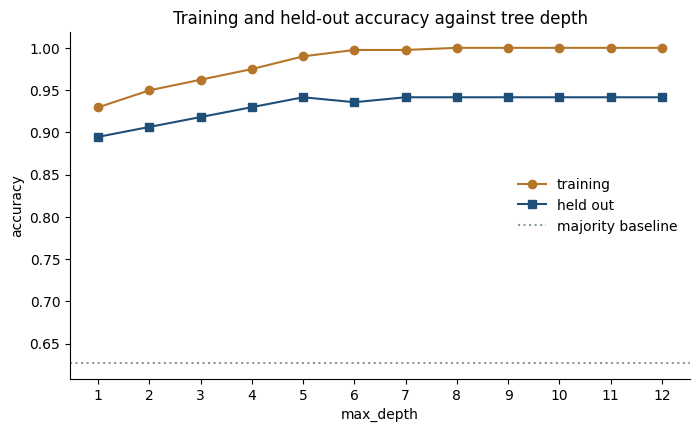

best held-out accuracy 0.9415 at depth 5


In [4]:
rows = []
for d in range(1, 13):
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d,
                               random_state=SEED).fit(X_train, y_train)
    rows.append({"depth": d,
                 "train": m.score(X_train, y_train),
                 "test": m.score(X_test, y_test),
                 "leaves": m.get_n_leaves()})
sweep = pd.DataFrame(rows)
display(sweep.style.format({"train": "{:.4f}", "test": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(sweep.depth, sweep.train, "-o", color="#b5762a", label="training")
ax.plot(sweep.depth, sweep.test, "-s", color="#1f4e79", label="held out")
ax.axhline(baseline, color="#8798a3", linestyle=":", label="majority baseline")
ax.set_xlabel("max_depth"); ax.set_ylabel("accuracy")
ax.set_xticks(sweep.depth); ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Training and held-out accuracy against tree depth")
plt.show()

best = sweep.loc[sweep.test.idxmax()]
print(f"best held-out accuracy {best.test:.4f} at depth {int(best.depth)}")

# 3.1  The curves separate once the training curve keeps climbing while the
#      held-out curve flattens. Past that depth the extra splits are dividing
#      handfuls of training cases: they describe those cases rather than the
#      relationship, so they buy training accuracy and nothing else.
# 3.2  The depth with the best held-out score looks like the answer, but it was
#      chosen BY LOOKING AT the held-out set, which means that score is no
#      longer an unbiased estimate of anything. Task 8 does it honestly.

## Task 4 — Audit the actual tree

Fit a depth-3 tree and print it with `export_text`. Then answer, from the tree
itself rather than from intuition:

**Question 4.1.** What is the root feature and what threshold was selected?
What does that feature mean biologically?

**Question 4.2.** Which leaves are pure, and which are mixed? How many training
cases are in the smallest leaf?

**Question 4.3.** Is any branch so specific that you would not trust it on a
new patient? Say which, and why.

|--- worst perimeter <= 112.80
|   |--- worst concave points <= 0.18
|   |   |--- mean texture <= 21.32
|   |   |   |--- weights: [196.00, 2.00] class: 0
|   |   |--- mean texture >  21.32
|   |   |   |--- weights: [45.00, 9.00] class: 0
|   |--- worst concave points >  0.18
|   |   |--- weights: [0.00, 8.00] class: 1
|--- worst perimeter >  112.80
|   |--- worst concave points <= 0.14
|   |   |--- mean texture <= 16.78
|   |   |   |--- weights: [5.00, 0.00] class: 0
|   |   |--- mean texture >  16.78
|   |   |   |--- weights: [4.00, 16.00] class: 1
|   |--- worst concave points >  0.14
|   |   |--- weights: [0.00, 113.00] class: 1



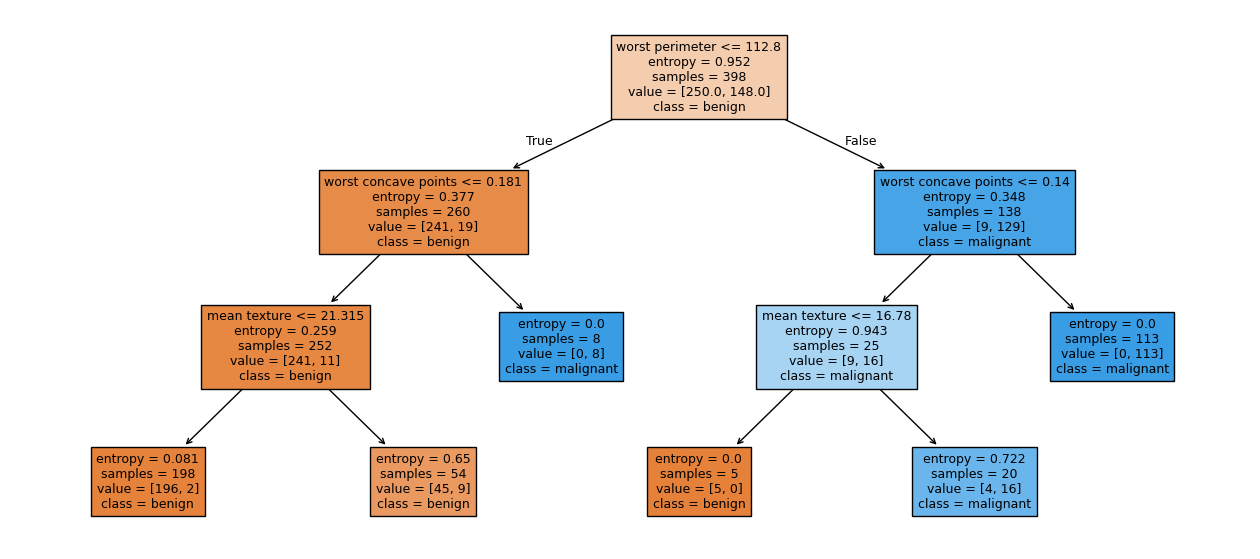

root: worst perimeter <= 112.8000


,node,samples,benign,malignant,entropy
0,3,198,196,2,0.0815
1,4,54,45,9,0.6500
2,5,8,0,8,0.0000
3,8,5,5,0,0.0000
4,9,20,4,16,0.7219
5,10,113,0,113,0.0000


In [5]:
tree3 = DecisionTreeClassifier(criterion="entropy", max_depth=3,
                               random_state=SEED).fit(X_train, y_train)
print(export_text(tree3, feature_names=feature_names, show_weights=True))

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree3, feature_names=feature_names,
          class_names=["benign", "malignant"], filled=True, fontsize=9,
          impurity=True, ax=ax)
plt.show()

t = tree3.tree_
root_feature = feature_names[t.feature[0]]
print(f"root: {root_feature} <= {t.threshold[0]:.4f}")

leaves = [i for i in range(t.node_count) if t.children_left[i] == -1]
info = []
for i in leaves:
    counts = t.value[i][0] * t.n_node_samples[i] if t.value[i][0].sum() <= 1.001 \
             else t.value[i][0]
    info.append({"node": i, "samples": int(t.n_node_samples[i]),
                 "benign": int(round(counts[0])),
                 "malignant": int(round(counts[1])),
                 "entropy": round(float(t.impurity[i]), 4)})
display(pd.DataFrame(info))

# 4.1  The root is the perimeter of the largest ("worst") nucleus found in the
#      image. Larger nuclei are associated with malignancy in this dataset.
#      The threshold is a value fitted to these 398 training cases; it is not a
#      clinical cut-off and it would move on different data.
# 4.2  Leaves with entropy 0.0 are pure. Read the smallest leaf's sample count
#      from the table: a leaf built from a handful of cases is a rule supported
#      by a handful of cases.
# 4.3  Any leaf with very few training cases. The tree states its prediction
#      there with exactly the same confidence as a leaf built from 113 cases,
#      and nothing in the output distinguishes them. That is a property of the
#      model, not of the data.

## Task 5 — Trace a real case

Take one case from the held-out set. **Before you run anything**, work out by
hand which leaf it will reach: read the root test, look up that feature's value
in the case, and follow the branch. Write your answer down.

Then use `decision_path` to check.

**Question 5.1.** Which tests did the tree apply, and in what order?

**Question 5.2.** How many of the 30 features were consulted? What happened to
the others?

In [6]:
case_index = 6
case = X_test[case_index]

node_indicator = tree3.decision_path(case.reshape(1, -1))
leaf_id = tree3.apply(case.reshape(1, -1))[0]
path = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]

print(f"true diagnosis : {'malignant' if y_test[case_index] else 'benign'}")
print(f"model predicts : "
      f"{'malignant' if tree3.predict(case.reshape(1, -1))[0] else 'benign'}")
print("\ndecision path")
for node in path:
    if node == leaf_id:
        counts = t.value[node][0]
        if counts.sum() <= 1.001:
            counts = counts * t.n_node_samples[node]
        print(f"  leaf {node}: {int(t.n_node_samples[node])} training cases, "
              f"{int(round(counts[0]))} benign, {int(round(counts[1]))} malignant")
        break
    f = feature_names[t.feature[node]]
    thr = t.threshold[node]
    val = case[t.feature[node]]
    went = "true (left)" if val <= thr else "false (right)"
    print(f"  {f} = {val:.4f}  <=  {thr:.4f} ?  {went}")

used = {feature_names[t.feature[node]] for node in path if node != leaf_id}
print(f"\nfeatures consulted: {len(used)} of {len(feature_names)}")

# 5.1  Read the printout above. The order is the order of the tests, root
#      first; that order is the decision path.
# 5.2  Only the handful named. The remaining features were never looked at for
#      this case. They may be highly informative for other cases; for this one
#      the tree reached a leaf before it needed them. This is why the decision
#      path is a description of what the model did, not an account of what
#      matters biologically.

true diagnosis : malignant
model predicts : malignant

decision path
  worst perimeter = 152.2000  <=  112.8000 ?  false (right)
  worst concave points = 0.1625  <=  0.1398 ?  false (right)
  leaf 10: 113 training cases, 0 benign, 113 malignant

features consulted: 2 of 30


## Task 6 — Deploy the model

Open the Week 2 page of the course website and scroll to **Deployment
demonstration**. It runs the same kind of tree, fitted in your browser on the
same data.

1. Press **Load example case** and read the prediction and the decision path.
2. Change one measurement by a small amount and analyse again.
3. Now change it until the prediction flips. How far did you have to go?
4. Enter something impossible, such as 900 for a perimeter, and see what the
   interface does.

**Question 6.1.** Which single measurement moved the prediction, and why that
one?

**Question 6.2.** The interface warns you when a value is outside the range
observed in the teaching dataset, but still returns a prediction. Is that the
right behaviour? Argue either way.

In [7]:
# 6.1  Whichever feature is tested on this case's path, most often the root.
#      Changing a feature the path never consults does nothing at all, however
#      biologically important that feature is. Students find this surprising
#      and it is the clearest demonstration of what a tree actually uses.
# 6.2  Defensible either way, and the argument matters more than the answer.
#      For: refusing to answer hides the model's behaviour, and a warned
#      extrapolation is more honest than a blank. Against: a prediction that
#      appears at all will be read as a prediction that is meant, and a warning
#      next to a confident-looking answer is routinely ignored. A real system
#      would usually refuse and log it.

## Task 7 — Mystery case

Below is a case with its label hidden. **Predict it yourself first**, using the
depth-3 tree you printed in Task 4. Write your prediction down before running
the cell that reveals the answer.

**Question 7.1.** Which split changed your mind, if any?

**Question 7.2.** If the model and you disagree, which of you is more likely to
be wrong, and how would you find out?

In [8]:
mystery = X_test[17]
my_prediction = "benign"

model_says = "malignant" if tree3.predict(mystery.reshape(1, -1))[0] else "benign"
truth = "malignant" if y_test[17] else "benign"

print(f"your prediction : {my_prediction}")
print(f"model predicts  : {model_says}")
print(f"true diagnosis  : {truth}")

node_indicator = tree3.decision_path(mystery.reshape(1, -1))
path = node_indicator.indices[node_indicator.indptr[0]:node_indicator.indptr[1]]
leaf_id = tree3.apply(mystery.reshape(1, -1))[0]
for node in path:
    if node == leaf_id:
        break
    print(f"  {feature_names[t.feature[node]]} = "
          f"{mystery[t.feature[node]]:.4f} <= {t.threshold[node]:.4f} ? "
          f"{'true' if mystery[t.feature[node]] <= t.threshold[node] else 'false'}")

# 7.1  Usually the root split: it carries the most information and it is the
#      one students weigh most heavily by eye as well.
# 7.2  Neither answer is evidence. The model is right about roughly nine
#      held-out cases in ten and has no idea which ten per cent it is wrong
#      about; you have seen the tree but not the 398 cases behind it. The way
#      to find out is not to argue about one case but to look at the confusion
#      matrix over all 171, which Task 8 does.

your prediction : benign
model predicts  : malignant
true diagnosis  : malignant
  worst perimeter = 157.6000 <= 112.8000 ? false
  worst concave points = 0.2255 <= 0.1398 ? false


## Task 8 — Validation, done properly

Task 3 chose a depth by looking at the held-out set. Do it honestly instead.

Split **60 / 20 / 20**: train, validation, final test. Choose `max_depth` on the
validation set. Then evaluate on the final test set **once**, and report the
confusion matrix.

**Question 8.1.** How does the final test accuracy compare with the validation
accuracy at the chosen depth? Which is the honest estimate?

**Question 8.2.** Why is repeatedly checking the final test set a problem, given
that you never train on it?

train 341   validation 114   final test 114
chosen depth 5 with validation accuracy 0.9561
FINAL TEST accuracy 0.9649


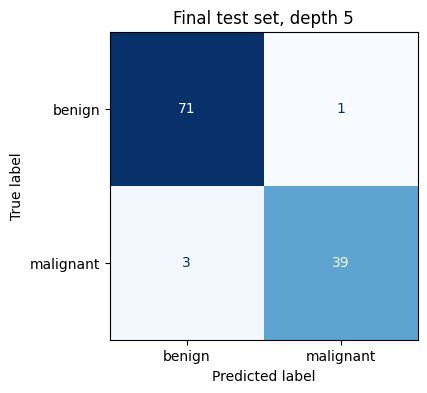

              precision    recall  f1-score   support

      benign       0.96      0.99      0.97        72
   malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114

false negatives (missed malignancies): 3


In [9]:
X_tr, X_tmp, y_tr, y_tmp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED)
X_val, X_fin, y_val, y_fin = train_test_split(
    X_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)
print(f"train {len(y_tr)}   validation {len(y_val)}   final test {len(y_fin)}")

scores = []
for d in range(1, 13):
    m = DecisionTreeClassifier(criterion="entropy", max_depth=d,
                               random_state=SEED).fit(X_tr, y_tr)
    scores.append((d, m.score(X_val, y_val)))
chosen_depth, val_acc = max(scores, key=lambda s: s[1])
print(f"chosen depth {chosen_depth} with validation accuracy {val_acc:.4f}")

final = DecisionTreeClassifier(criterion="entropy", max_depth=chosen_depth,
                               random_state=SEED).fit(X_tr, y_tr)
fin_acc = final.score(X_fin, y_fin)        # looked at exactly once
print(f"FINAL TEST accuracy {fin_acc:.4f}")

cm = confusion_matrix(y_fin, final.predict(X_fin))
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"]).plot(
    ax=ax, colorbar=False, cmap="Blues")
ax.set_title(f"Final test set, depth {chosen_depth}")
plt.show()
print(classification_report(y_fin, final.predict(X_fin),
                            target_names=["benign", "malignant"]))
print(f"false negatives (missed malignancies): {cm[1][0]}")

# 8.1  The final test figure is the honest estimate, because it is the only
#      number produced by data that took no part in any decision. It is NOT
#      guaranteed to be lower: on this seed it comes out slightly higher than
#      the validation score. With 114 cases, two cases is 1.8 percentage
#      points, so differences of that size are noise. The point is not that
#      validation flatters you by a predictable amount; it is that the
#      validation number is not an estimate of anything, because it was the
#      quantity being maximised.
# 8.2  Because choosing is a form of fitting. Every time you look at the test
#      set and change something, you move your model towards that particular
#      sample. Nothing was trained on it, but information leaked out of it into
#      your choices, and the number stops describing unseen data.

## Task 9 — Pruning

Compare an unpruned tree with a pruned one. Use
`cost_complexity_pruning_path` to get the candidate `ccp_alpha` values, fit a
tree at each, and plot accuracy and the number of leaves against alpha.

**Visualise both trees.**

**Question 9.1.** What does pruning cost you, and what does it buy?

**Question 9.2.** Choose alpha on the validation set from Task 8, not on the
test set. Does the honest choice agree with the one that maximises test
accuracy?

,alpha,leaves,train,validation,final_test
0,0.00808,14,0.9971,0.9211,0.9561
1,0.00948,12,0.9941,0.9211,0.9561
2,0.00952,11,0.9912,0.9298,0.9649
3,0.01144,10,0.9883,0.9298,0.9649
4,0.01322,9,0.9853,0.9298,0.9649
5,0.02400,8,0.9795,0.9211,0.9561
6,0.02521,7,0.9677,0.9386,0.9474
7,0.02981,6,0.9589,0.9298,0.9298
8,0.03382,5,0.9560,0.9298,0.9298
9,0.03663,3,0.9560,0.9298,0.9298


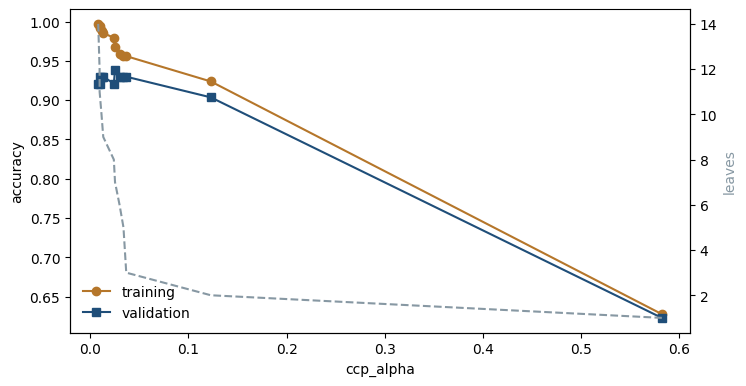

alpha chosen on validation : 0.02521
alpha that would maximise the final test set: 0.00952


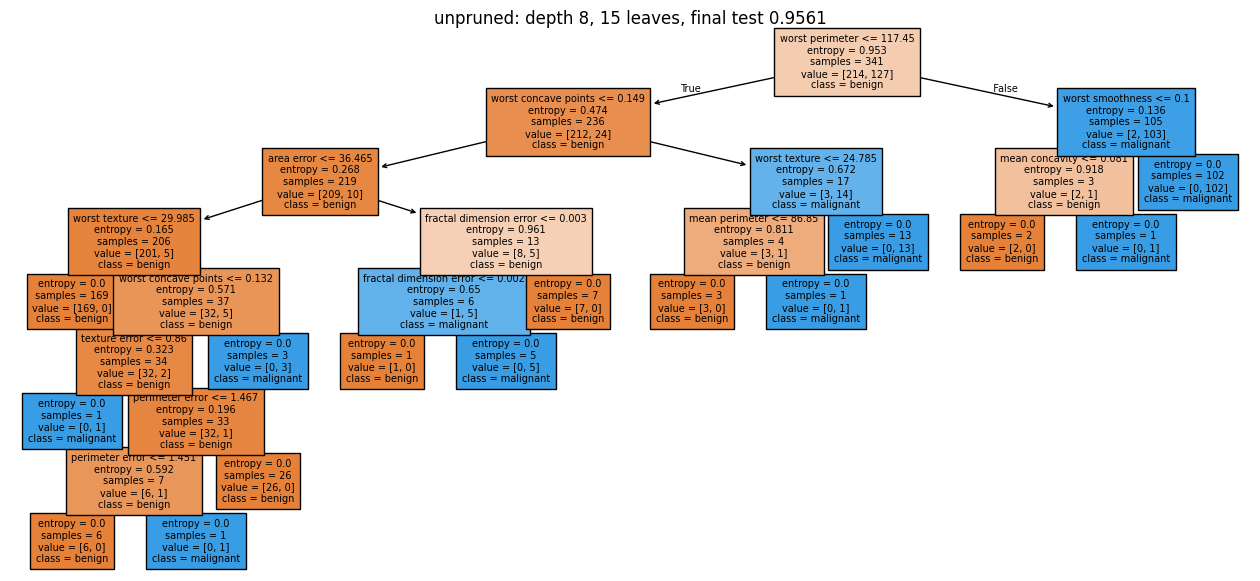

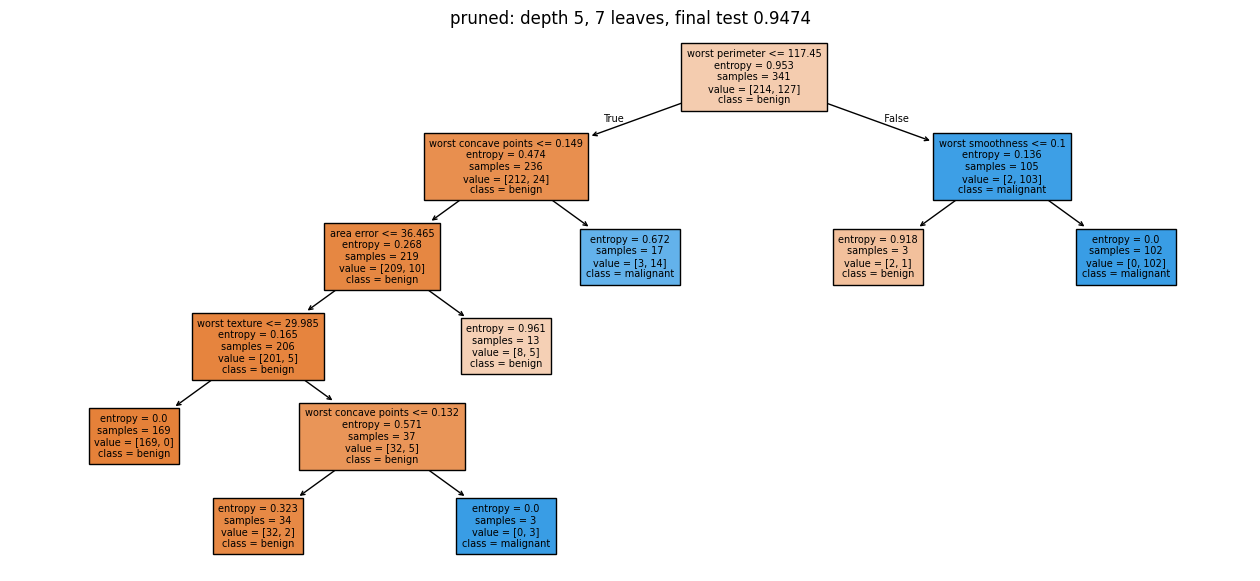

In [10]:
path = DecisionTreeClassifier(criterion="entropy", random_state=SEED) \
    .cost_complexity_pruning_path(X_tr, y_tr)
alphas = [a for a in path.ccp_alphas if a > 0]

rows = []
for a in alphas:
    m = DecisionTreeClassifier(criterion="entropy", ccp_alpha=a,
                               random_state=SEED).fit(X_tr, y_tr)
    rows.append({"alpha": a, "leaves": m.get_n_leaves(),
                 "train": m.score(X_tr, y_tr),
                 "validation": m.score(X_val, y_val),
                 "final_test": m.score(X_fin, y_fin)})
pr = pd.DataFrame(rows)
display(pr.style.format({"alpha": "{:.5f}", "train": "{:.4f}",
                         "validation": "{:.4f}", "final_test": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(pr.alpha, pr.train, "-o", color="#b5762a", label="training")
ax.plot(pr.alpha, pr.validation, "-s", color="#1f4e79", label="validation")
ax2 = ax.twinx()
ax2.plot(pr.alpha, pr.leaves, "--", color="#8798a3")
ax2.set_ylabel("leaves", color="#8798a3")
ax.set_xlabel("ccp_alpha"); ax.set_ylabel("accuracy")
ax.legend(frameon=False, loc="lower left")
ax.spines[["top"]].set_visible(False)
plt.show()

honest_alpha = pr.loc[pr.validation.idxmax(), "alpha"]
peeking_alpha = pr.loc[pr.final_test.idxmax(), "alpha"]
print(f"alpha chosen on validation : {honest_alpha:.5f}")
print(f"alpha that would maximise the final test set: {peeking_alpha:.5f}")

unpruned = DecisionTreeClassifier(criterion="entropy",
                                  random_state=SEED).fit(X_tr, y_tr)
pruned = DecisionTreeClassifier(criterion="entropy", ccp_alpha=honest_alpha,
                                random_state=SEED).fit(X_tr, y_tr)
for m, name in ((unpruned, "unpruned"), (pruned, "pruned")):
    fig, ax = plt.subplots(figsize=(16, 7))
    plot_tree(m, feature_names=feature_names,
              class_names=["benign", "malignant"], filled=True, fontsize=7, ax=ax)
    ax.set_title(f"{name}: depth {m.get_depth()}, {m.get_n_leaves()} leaves, "
                 f"final test {m.score(X_fin, y_fin):.4f}")
    plt.show()

# 9.1  Pruning costs training accuracy, always, and it can cost a little
#      held-out accuracy if you cut too far. It buys a smaller tree: fewer
#      rules, each supported by more cases, and a model a person can read and
#      argue with.
# 9.2  Often they differ, and that difference IS the lesson. The alpha that
#      maximises the final test set is not available to you in practice,
#      because using it would mean choosing on the test set. Report the honest
#      one.

## Task 10 — Model card

Write a model card for the depth-3 tree, in the markdown cell below. This is
the deliverable. It follows Mitchell et al. (2019).

Cover, in your own words:

- **Intended use.** What is this model for, and who would use it?
- **Data.** What is in it, where did it come from, when, and who is missing?
- **Features.** What are they, and how are they obtained?
- **Model.** Type, criterion, hyperparameters, how they were chosen, and the
  random seed.
- **Evidence.** Which numbers, measured on what, with what protocol.
- **Limitations.** Where does it fail, and how would you know?
- **Risks.** What are the consequences of each error type, and who bears them?
- **Why this is not a clinical system.** Be specific.

**Be honest about the protocol you actually followed**, including anywhere you
looked at the test set. A model card that describes an idealised process is
worse than none.

### Model card — decision tree for WDBC diagnosis

**Intended use.** Teaching artefact for COMP9085. It exists so that students
can inspect a fitted model end to end. It has no intended operational use, and
no user other than a student.

**Data.** Wisconsin Diagnostic Breast Cancer, 569 cases, 212 malignant and 357
benign, collected at a single institution (University of Wisconsin) and
published in 1995. No demographic information is recorded, so representation
cannot be checked at all. Whoever is missing from this sample is invisible.

**Features.** Thirty numerical features derived from digitised images of
fine-needle aspirates: ten nuclear measurements, each summarised by mean,
standard error and worst value. They require a trained person to trace nuclei
from an image, so they are not available at the point most decisions are made.

**Model.** `DecisionTreeClassifier`, CART-style binary splitting,
`criterion='entropy'`, `max_depth` chosen on a validation set, `random_state=42`.
Not ID3, despite the splitting criterion being the one ID3 uses.

**Evidence.** 60/20/20 stratified split. Depth chosen on the validation set;
the final test set was evaluated once. Report the final test accuracy and the
confusion matrix from Task 8, and state the majority baseline (0.627) beside
them. Earlier in this notebook, Task 3 chose a depth by looking at the held-out
set; that figure is optimistic and is not the one reported here.

**Limitations.** Single institution, single era, single imaging protocol.
Performance under a different scanner, laboratory or population is unknown and
untested. The decision path a case follows consults only a handful of the
thirty features, so the model is silent about the rest. Small leaves state
their predictions with the same apparent confidence as large ones.

**Risks.** A false negative is a missed malignancy. A false positive is an
unnecessary intervention and considerable distress. Accuracy weights them
equally; no clinical context does. The patient bears both, and neither appears
in the loss function used to fit this tree.

**Why this is not a clinical system.** It has no regulatory approval, no
external validation, no prospective evaluation, no monitoring, no defined
operator, and no defined action on its output. It was fitted to 341 cases from
one hospital in the 1990s by a student in a two-hour laboratory. Interpretable
is not the same as correct.

---

## Before you leave

Check that you can answer these without looking anything up.

1. Why did the tree ask about the root feature first? Give the number.
2. What is the difference between the decision path and an explanation?
3. Which accuracy from this notebook would you put in a report, and which would you refuse to?
4. Name one thing that would have to be true before this model could be used on a patient, and say whether it is true.
